In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")


Preprocessing

In [2]:
df = pd.read_excel("/content/online_retail_II.xlsx")

df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [20]:
print("Rows and columns:", df.shape)

df.info()

Rows and columns: (410763, 9)
<class 'pandas.core.frame.DataFrame'>
Index: 410763 entries, 0 to 525460
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      410763 non-null  object        
 1   StockCode    410763 non-null  object        
 2   Description  410763 non-null  object        
 3   Quantity     410763 non-null  int64         
 4   InvoiceDate  410763 non-null  datetime64[ns]
 5   Price        410763 non-null  float64       
 6   Customer ID  410763 non-null  float64       
 7   Country      410763 non-null  object        
 8   TotalAmount  410763 non-null  float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(4)
memory usage: 31.3+ MB


In [21]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID,TotalAmount
count,410763.000000,410763,410763.000000,410763.000000,410763.000000
mean,12.923735,2010-06-30 19:56:14.853674752,3.908358,15353.621857,20.242465
min,-9360.000000,2009-12-01 07:45:00,0.000000,12346.000000,-25111.090000
25%,2.000000,2010-03-26 09:46:00,1.250000,13979.000000,4.500000
50%,5.000000,2010-07-08 15:09:00,1.950000,15311.000000,11.800000
75%,12.000000,2010-10-14 12:32:00,3.750000,16797.000000,19.500000
max,19152.000000,2010-12-09 20:01:00,25111.090000,18287.000000,15818.400000
std,102.039550,NaN,71.714794,1681.657665,100.710825


In [22]:
print("Missing values:\n", df.isnull().sum())


Missing values:
 Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
TotalAmount    0
dtype: int64


In [23]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [24]:
df = df.dropna()

In [25]:
df = df.drop_duplicates()

In [26]:
df.shape

(410763, 9)

In [27]:

print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

Date range: 2009-12-01 07:45:00 to 2010-12-09 20:01:00


In [28]:
df["TotalAmount"] = df["Quantity"] * df["Price"]

rfm score

In [29]:
reference_date = df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

rfm = df.groupby("Customer ID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("Invoice", "nunique"),
    Monetary=("TotalAmount", "sum")
)
rfm["Recency"] = (reference_date - rfm["LastPurchase"]).dt.days
rfm = rfm[["Recency", "Frequency", "Monetary"]].copy()
print("Customer-level RFM shape:", rfm.shape)
rfm.head()

Customer-level RFM shape: (4383, 3)


,Recency,Frequency,Monetary
Customer ID,,,
12346.0,66,15,-51.74
12347.0,2,2,1323.32
12348.0,73,1,222.16
12349.0,42,4,2646.99
12351.0,10,1,300.93


In [30]:
rfm.describe().round(2)

,Recency,Frequency,Monetary
count,4383.00,4383.00,4383.00
mean,90.40,5.38,1897.07
std,98.18,10.05,8516.92
min,0.00,1.00,-25111.09
25%,16.00,1.00,282.88
50%,51.00,3.00,652.45
75%,137.00,6.00,1633.62
max,373.00,270.00,341776.73


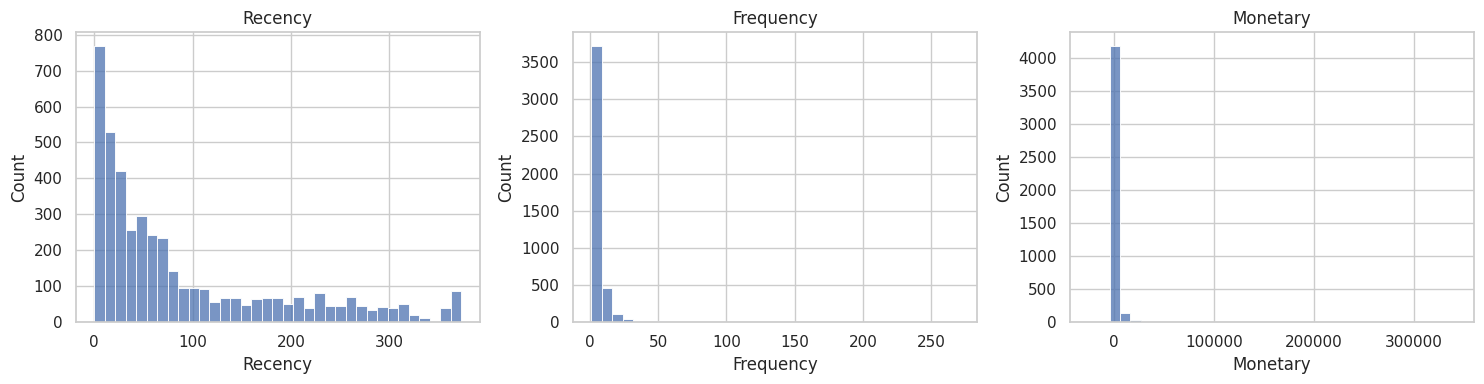

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, ["Recency", "Frequency", "Monetary"]):
    sns.histplot(rfm[column], bins=35, ax=ax)
    ax.set_title(column)
plt.tight_layout()
plt.show()

K means cluster

In [32]:

features = rfm[["Recency", "Frequency", "Monetary"]].copy()


features = features.replace([np.inf, -np.inf], np.nan)


features = features.dropna()


features = features[(features >= 0).all(axis=1)]


rfm = rfm.loc[features.index].copy()

print("RFM shape after cleaning:", features.shape)
print("Missing values:\n", features.isnull().sum())
print("Negative values:\n", (features < 0).sum())

# Apply log transformation to reduce skewness
features_log = np.log1p(features)

# Standardize the features
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features_log)

print("Scaled data shape:", features_scaled.shape)
print("Contains NaN:", np.isnan(features_scaled).any())
print("Contains infinity:", np.isinf(features_scaled).any())

RFM shape after cleaning: (4293, 3)
Missing values:
 Recency      0
Frequency    0
Monetary     0
dtype: int64
Negative values:
 Recency      0
Frequency    0
Monetary     0
dtype: int64
Scaled data shape: (4293, 3)
Contains NaN: False
Contains infinity: False


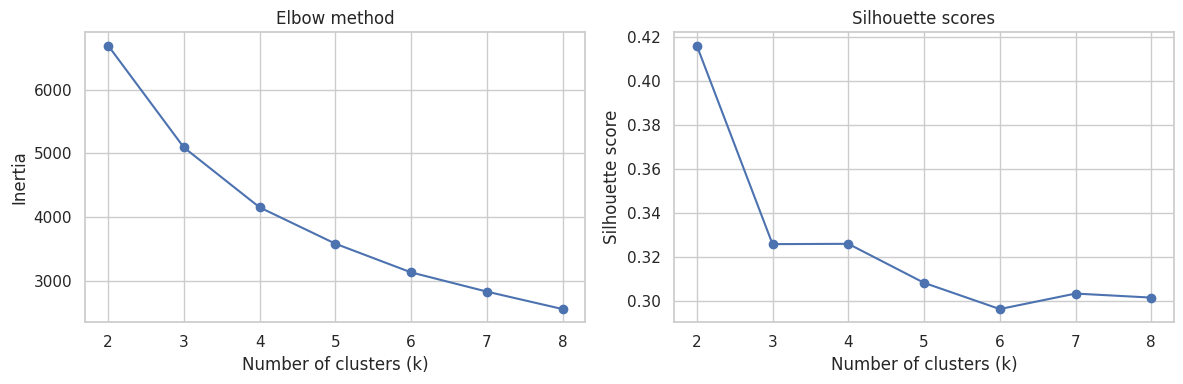

,k,inertia,silhouette
0,2,6689.434,0.416
1,3,5094.115,0.326
2,4,4156.690,0.326
3,5,3588.088,0.308
4,6,3138.857,0.296
5,7,2838.007,0.303
6,8,2564.770,0.302


In [33]:
k_values = list(range(2, 9))
inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(features_scaled)
    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(features_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_values, inertias, marker="o")
axes[0].set(title="Elbow method", xlabel="Number of clusters (k)", ylabel="Inertia")
axes[1].plot(k_values, silhouette_scores, marker="o")
axes[1].set(title="Silhouette scores", xlabel="Number of clusters (k)", ylabel="Silhouette score")
plt.tight_layout()
plt.show()

score_table = pd.DataFrame({"k": k_values, "inertia": inertias, "silhouette": silhouette_scores})
display(score_table.round(3))

In [34]:
# Start with the best silhouette score. You may manually change best_k after checking the elbow plot.
best_k = k_values[int(np.argmax(silhouette_scores))]
print("Selected k:", best_k)

kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(features_scaled)
print("Final silhouette score:", round(silhouette_score(features_scaled, rfm["Cluster"]), 3))
print(rfm["Cluster"].value_counts().sort_index())

Selected k: 2
Final silhouette score: 0.416
Cluster
0    1728
1    2565
Name: count, dtype: int64


## 8. PCA: reduce 3 RFM dimensions to 2
PCA finds directions of maximum variance in the **scaled, log-transformed** RFM features. These components are for visualization; K-Means was fitted on all three standardized features.

In [35]:
pca = PCA(n_components=2)
rfm_pca = pca.fit_transform(features_scaled)
rfm["PC1"] = rfm_pca[:, 0]
rfm["PC2"] = rfm_pca[:, 1]

print("Explained variance ratio:", pca.explained_variance_ratio_.round(3))
print("Total explained variance:", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

loadings = pd.DataFrame(pca.components_.T, index=["Recency", "Frequency", "Monetary"], columns=["PC1", "PC2"])
display(loadings.round(3))

Explained variance ratio: [0.731 0.199]
Total explained variance: 93.01 %


,PC1,PC2
Recency,-0.505,0.858
Frequency,0.619,0.278
Monetary,0.602,0.433


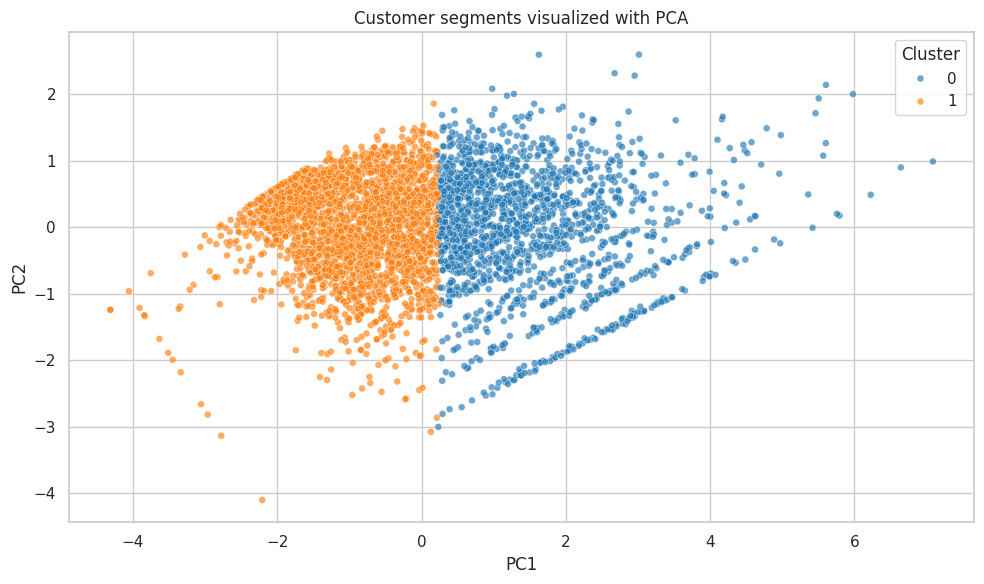

In [36]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=rfm.reset_index(), x="PC1", y="PC2", hue="Cluster", palette="tab10", s=25, alpha=0.65)
plt.title("Customer segments visualized with PCA")
plt.tight_layout()
plt.show()

In [39]:
median_r = rfm["Recency"].median()
median_f = rfm["Frequency"].median()
median_m = rfm["Monetary"].median()

def assign_persona(row):
    recent = row["AvgRecency"] <= median_r
    frequent = row["AvgFrequency"] > median_f
    high_spend = row["AvgMonetary"] > median_m

    if recent and frequent and high_spend:
        return "Champions", "VIP rewards, early product access, referral offers"
    elif not recent and (frequent or high_spend):
        return "At-risk valuable", "Win-back email, personalized offers, feedback survey"
    elif recent and high_spend:
        return "High-spending potential", "Cross-sell bundles and loyalty enrollment"
    elif recent and frequent:
        return "Active regulars", "Points program and relevant recommendations"
    elif recent:
        return "Recent / occasional", "Second-purchase incentive and onboarding"
    else:
        return "Dormant / low-engagement", "Low-cost reactivation campaign; avoid overspending"

profile[["Persona", "RecommendedAction"]] = profile.apply(lambda row: pd.Series(assign_persona(row)), axis=1)

display(profile[["Customers", "CustomerSharePct", "AvgRecency", "AvgFrequency", "AvgMonetary", "RevenueSharePct", "Persona", "RecommendedAction"]].round(2))

,Customers,CustomerSharePct,AvgRecency,AvgFrequency,AvgMonetary,RevenueSharePct,Persona,RecommendedAction
Cluster,,,,,,,,
0,1728,40.25,28.25,10.63,4161.89,85.52,Champions,"VIP rewards, early product access, referral of..."
1,2565,59.75,127.76,1.96,474.75,14.48,Dormant / low-engagement,Low-cost reactivation campaign; avoid overspen...


In [40]:
for cluster, row in profile.iterrows():
    print(f"Cluster {cluster}: {row['Persona']}")
    print(f"  Customers: {int(row['Customers'])} | Average recency: {row['AvgRecency']:.1f} days")
    print(f"  Average orders: {row['AvgFrequency']:.1f} | Average spend: £{row['AvgMonetary']:.2f}")
    print(f"  Revenue share: {row['RevenueSharePct']:.1f}%")
    print(f"  Marketing action: {row['RecommendedAction']}\n")

Cluster 0: Champions
  Customers: 1728 | Average recency: 28.3 days
  Average orders: 10.6 | Average spend: £4161.89
  Revenue share: 85.5%
  Marketing action: VIP rewards, early product access, referral offers

Cluster 1: Dormant / low-engagement
  Customers: 2565 | Average recency: 127.8 days
  Average orders: 2.0 | Average spend: £474.75
  Revenue share: 14.5%
  Marketing action: Low-cost reactivation campaign; avoid overspending

